# Webinar 1 — Data Analytics dan AI: Analisis Penjualan Online

Analisis transaksi nyata dari UCI Online Retail. Notebook membersihkan data, membuat KPI dan tren penjualan, lalu mencoba baseline prediksi penjualan harian. Jalankan seluruh sel secara berurutan.

In [1]:
import io, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

## 1. Unduh dan baca dataset resmi
Dataset berisi transaksi toko online Inggris periode 2010–2011. File Excel cukup besar; proses agregasi harian agar notebook ringan.

In [2]:
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
with urllib.request.urlopen(url) as response:
    archive_bytes = response.read()
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as zf:
    excel_name = next(n for n in zf.namelist() if n.lower().endswith(('.xlsx', '.xls')))
    df = pd.read_excel(zf.open(excel_name))
print("Bentuk data:", df.shape)
display(df.head())
print(df.dtypes)

Bentuk data: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


## 2. Pembersihan dan KPI

In [3]:
df.columns = [str(c).strip() for c in df.columns]
df = df.dropna(subset=["InvoiceNo", "Description", "Quantity", "InvoiceDate", "UnitPrice"]).copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
# Invoice yang diawali C merupakan pembatalan; keluarkan dari penjualan bersih.
df = df[(~df["InvoiceNo"].str.startswith("C")) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
df["Sales"] = df["Quantity"] * df["UnitPrice"]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df = df.dropna(subset=["InvoiceDate"])
df["Date"] = df["InvoiceDate"].dt.floor("D")
print("Jumlah transaksi baris setelah dibersihkan:", len(df))
print("Omzet kotor terhitung (£):", round(df["Sales"].sum(), 2))
print("Jumlah invoice:", df["InvoiceNo"].nunique())
print("Jumlah pelanggan teridentifikasi:", df["CustomerID"].nunique() if "CustomerID" in df else "kolom tidak tersedia")

Jumlah transaksi baris setelah dibersihkan: 530104
Omzet kotor terhitung (£): 10666684.54
Jumlah invoice: 19960
Jumlah pelanggan teridentifikasi: 4338


## 3. Visualisasi tren dan produk terlaris

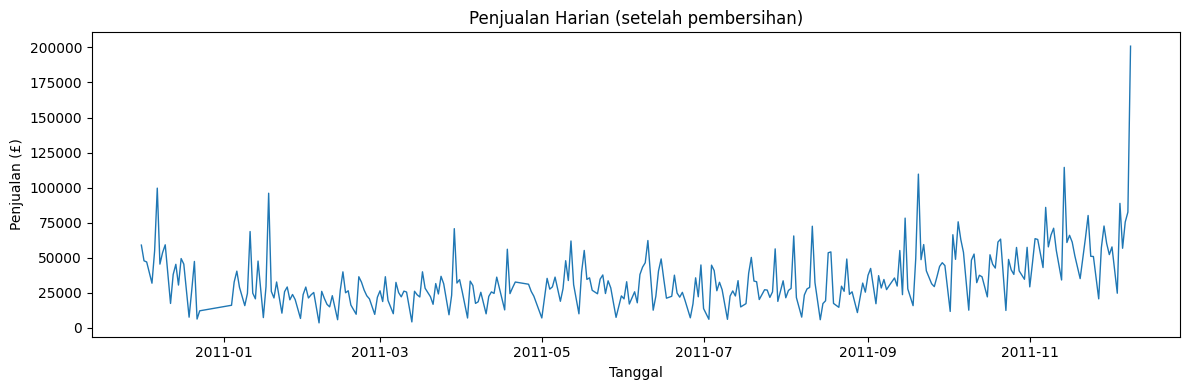

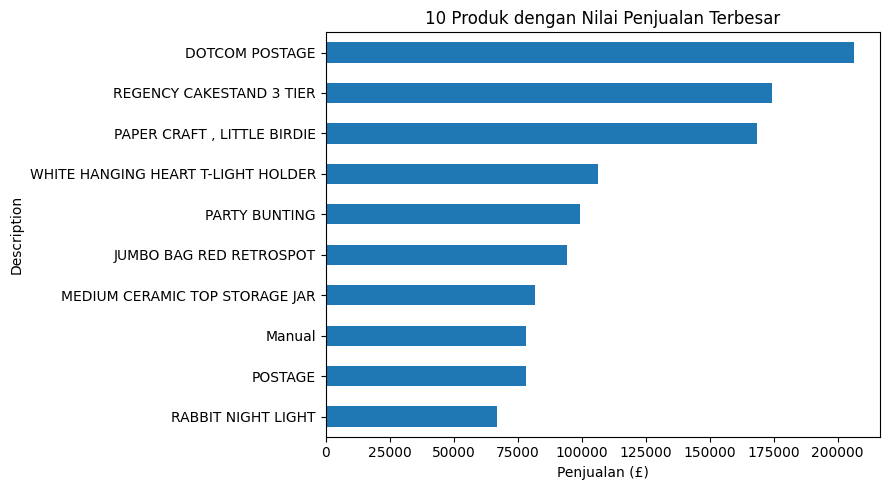

,Date,Sales
0,2010-12-01,58960.79
1,2010-12-02,47748.38
2,2010-12-03,46943.71
3,2010-12-05,31774.95
4,2010-12-06,54830.46


In [4]:
daily = df.groupby("Date", as_index=False)["Sales"].sum().sort_values("Date")
plt.figure(figsize=(12,4)); plt.plot(daily["Date"], daily["Sales"], linewidth=1)
plt.title("Penjualan Harian (setelah pembersihan)"); plt.xlabel("Tanggal"); plt.ylabel("Penjualan (£)"); plt.tight_layout(); plt.show()
top_products = df.groupby("Description")["Sales"].sum().sort_values(ascending=False).head(10).sort_values()
plt.figure(figsize=(9,5)); top_products.plot(kind="barh"); plt.title("10 Produk dengan Nilai Penjualan Terbesar"); plt.xlabel("Penjualan (£)"); plt.tight_layout(); plt.show()
display(daily.head())

## 4. Baseline prediksi penjualan harian
Pembagian berdasarkan urutan waktu untuk menghindari data masa depan masuk ke pelatihan. Fitur lag sederhana; ini demonstrasi, bukan sistem forecasting produksi.

MAE: £17183.55 | RMSE: £27418.88


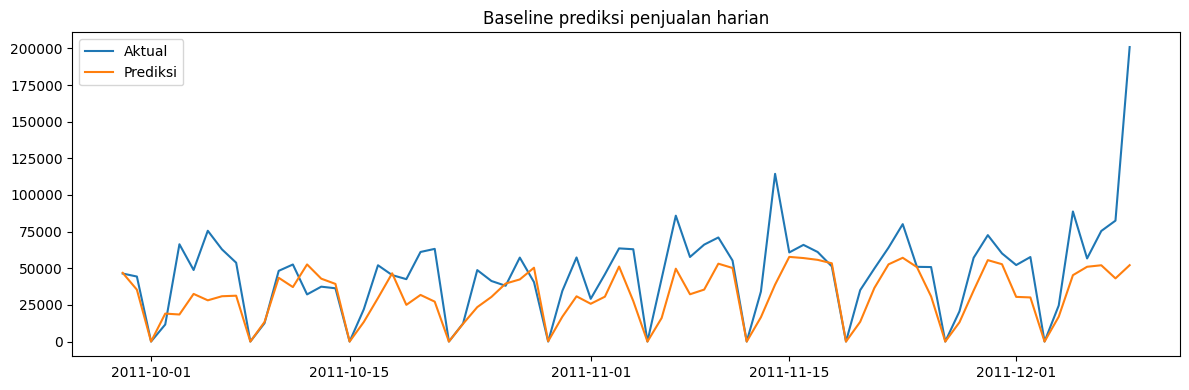

In [5]:
daily = daily.set_index("Date").asfreq("D", fill_value=0).reset_index()
for lag in [1, 7, 14]: daily[f"lag_{lag}"] = daily["Sales"].shift(lag)
daily["dayofweek"] = daily["Date"].dt.dayofweek
model_df = daily.dropna().copy()
features = ["lag_1", "lag_7", "lag_14", "dayofweek"]
split = int(len(model_df)*0.8)
train, test = model_df.iloc[:split], model_df.iloc[split:]
model = RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1)
model.fit(train[features], train["Sales"])
pred = model.predict(test[features])
mae = mean_absolute_error(test["Sales"], pred)
rmse = mean_squared_error(test["Sales"], pred)**0.5
print(f"MAE: £{mae:.2f} | RMSE: £{rmse:.2f}")
plt.figure(figsize=(12,4)); plt.plot(test["Date"],test["Sales"],label="Aktual"); plt.plot(test["Date"],pred,label="Prediksi"); plt.legend(); plt.title("Baseline prediksi penjualan harian"); plt.tight_layout(); plt.show()

## 5. Simpan hasil agar bisa dimasukkan ke repository

In [6]:
daily.to_csv("daily_sales_clean.csv", index=False)
print("File daily_sales_clean.csv disimpan di runtime Colab. Unduh jika ingin mengarsipkan hasil.")

File daily_sales_clean.csv disimpan di runtime Colab. Unduh jika ingin mengarsipkan hasil.
